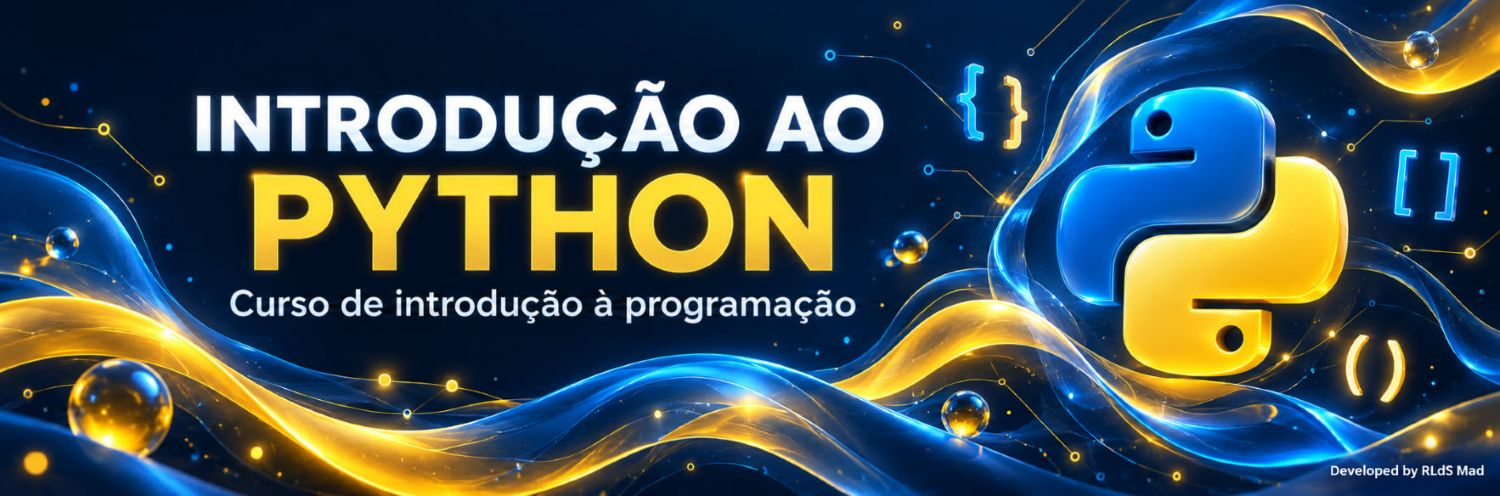

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_12_Redes_Sequencias.ipynb)

# Nível IA · Módulo 12 – Redes para sequências
## RNN, LSTM e atenção: como uma rede se lembra do passado

Uma frase, uma série temporal, um sinal de áudio ou uma sequência de cliques têm uma coisa em comum: a **ordem** importa. «O cão mordeu o homem» não é o mesmo que «o homem mordeu o cão». As redes dos módulos anteriores não foram feitas para isto: a rede densa do N3_04 olha para um vetor de tamanho fixo, e a CNN do N3_06 procura padrões locais numa grelha.

Este módulo constrói, de raiz, as três ideias que dominaram o processamento de sequências: a **rede recorrente** (RNN), que lê a sequência passo a passo com uma memória; a **LSTM**, que resolve o problema de a memória da RNN se apagar; e a **atenção**, que deixa cada posição olhar diretamente para todas as outras e é a base dos *transformers* e dos grandes modelos de linguagem. Uma mesma tarefa de memória serve de banco de ensaio para as três, para se ver **quando** e **porquê** cada uma funciona.

> **Objetivos:** perceber a ideia de viés indutivo e situar cada arquitetura de rede no tipo de dados para que foi pensada; representar sequências como tensores; implementar uma RNN de raiz e confirmar que coincide com `nn.RNN`; medir o desvanecimento do gradiente ao longo do tempo e perceber a sua causa; compreender as portas da LSTM e o estado da célula; implementar a atenção $\text{softmax}(QK^T/\sqrt{d})\,V$ e a codificação posicional; comparar RNN, LSTM e atenção numa tarefa de memória longa; relacionar o bloco de atenção com os *transformers* do N3_07.

**Pré-requisitos:** N3_04 (neurónios, ativações, retropropagação) e N3_05 (tensores, `nn.Module`, ciclo de treino). O N3_07 (texto e *embeddings*) ajuda na secção 6.

| Secção | Tema |
| --- | --- |
| 0. Preparação | PyTorch, bibliotecas e vocabulário |
| 1. Um mapa das arquiteturas | o viés indutivo de cada rede |
| 2. Sequências como dados | a forma (N, T, F) e a tarefa de memória |
| 3. A rede recorrente (RNN) | de raiz, e igual ao `nn.RNN` |
| 4. O gradiente que desvanece | porque a RNN esquece |
| 5. LSTM: uma memória com portas | o estado da célula e as portas |
| 6. Atenção | olhar diretamente para o passado |
| 7. Comparação e síntese | memória, paralelismo e custo |
| 8. Experimenta | três exercícios com solução |

## 0. Preparação

### 0.1 PyTorch e bibliotecas

No **Colab**, o PyTorch já vem instalado. No teu computador, segue as instruções do N3_05 (secção 0.1). As redes deste módulo são pequenas e treinam no CPU em poucos segundos cada.

In [1]:
# Executar esta célula

import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    import torch
    from torch import nn
except ImportError:
    raise ImportError("O PyTorch não está instalado. Vê a secção 0.1 do N3_05.")

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.manual_seed(0)
np.random.seed(0)
print(f"PyTorch {torch.__version__}")

PyTorch 2.15.0+cu132


### 0.2 Vocabulário

| Termo | Significado |
| --- | --- |
| **Sequência** | uma lista ordenada de elementos (*tokens*, medições, palavras); o comprimento é $T$ |
| **Passo** (*time step*) | uma posição $t$ da sequência |
| **Estado escondido** $h_t$ | o vetor que a rede recorrente guarda depois de ler o passo $t$: a sua «memória» |
| **Viés indutivo** | aquilo que uma arquitetura assume sobre os dados antes de os ver (por exemplo, que a ordem importa, ou que padrões próximos estão relacionados) |
| ***Embedding*** | um vetor denso aprendido que representa um *token* (N3_07) |
| **Porta** (*gate*) | um vetor de valores entre 0 e 1 que decide quanto de uma informação passa |
| **Atenção** | uma média ponderada de todos os elementos de uma sequência, com pesos calculados a partir dos próprios dados |
| **Consulta, chave e valor** ($Q$, $K$, $V$) | as três projeções usadas na atenção: a consulta pergunta, as chaves respondem «quão relevante sou», os valores são o que se mistura |

## 1. Um mapa das arquiteturas

Há muitas arquiteturas de redes neuronais, mas quase todas são variações de poucas ideias. O que as distingue é o **viés indutivo**: o que cada uma assume sobre a estrutura dos dados. Uma arquitetura que assume a estrutura certa precisa de menos dados e generaliza melhor; uma que assume a errada desperdiça parâmetros ou falha.

| Arquitetura | Dados para que foi pensada | O que assume | Neste tutorial |
| --- | --- | --- | --- |
| **MLP** (rede densa) | tabelas, vetores de tamanho fixo | nada sobre a ordem ou a vizinhança das entradas | N3_04, N3_05 |
| **CNN** (convolucional) | imagens, grelhas | padrões **locais**, iguais em qualquer posição | N3_06 |
| **RNN / LSTM** (recorrentes) | sequências | a **ordem** importa; o passado resume-se num estado | **este módulo** |
| **Transformer** (atenção) | sequências, conjuntos | qualquer elemento pode depender de qualquer outro | **este módulo** e N3_07 |
| **Autoencoder** | qualquer tipo | os dados vivem num espaço de **poucas dimensões** | N3_13 |
| **GAN** (adversarial) | imagens, dados para gerar | uma distribuição aprende-se por competição entre duas redes | N3_13 |
| **GNN** (redes de grafos) | grafos, redes | um nó depende dos seus **vizinhos** | N3_13 |

O resto deste módulo trata das sequências; o N3_13 trata das três últimas linhas e fecha com uma síntese de todas.

## 2. Sequências como dados

### 2.1 A forma (N, T, F)

Um lote de sequências é um tensor com três dimensões: **N** sequências, cada uma com **T** passos, cada passo descrito por **F** números. Uma série de temperaturas diárias tem F = 1; uma frase com *embeddings* de dimensão 16 tem F = 16. No PyTorch, as camadas recorrentes aceitam esta ordem com `batch_first=True`.

Porque não usar simplesmente uma rede densa sobre os T × F números? Por três razões: as sequências têm comprimentos diferentes; uma rede densa aprenderia pesos **separados** para cada posição (o que aprende sobre a palavra na posição 3 não serve para a posição 7); e o número de parâmetros cresceria com T.

### 2.2 A tarefa de memória

Para comparar as arquiteturas, usamos uma tarefa simples de enunciar e difícil para uma rede: a sequência tem $T$ símbolos ao acaso, de um alfabeto de 4 (0, 1, 2, 3), e a rede tem de responder, **no fim**, qual era o **primeiro** símbolo. Tudo o que vem depois do primeiro é ruído. Ao acaso, acerta-se 25 % das vezes. Aumentando $T$, controlamos exatamente quanto tempo a informação tem de ser lembrada.

In [2]:
# Executar esta célula

K = 4  # tamanho do alfabeto


def dados_memoria(n, T, semente=0):
    gerador = torch.Generator().manual_seed(semente)
    simbolos = torch.randint(0, K, (n, T), generator=gerador)
    return simbolos, simbolos[:, 0].clone()  # a resposta é o primeiro símbolo


x, y = dados_memoria(3, 10)
for sequencia, resposta in zip(x, y):
    print(sequencia.tolist(), "-> resposta:", resposta.item())
print("Forma do lote:", tuple(x.shape), "(N, T); depois do embedding fica (N, T, F)")

[0, 3, 1, 0, 3, 3, 3, 3, 1, 3] -> resposta: 0
[1, 2, 0, 3, 2, 0, 0, 0, 2, 1] -> resposta: 1
[2, 3, 3, 2, 0, 1, 1, 1, 1, 0] -> resposta: 2
Forma do lote: (3, 10) (N, T); depois do embedding fica (N, T, F)


Todas as redes do módulo usam o mesmo ciclo de treino: lotes novos em cada passo (os dados são infinitos), a perda de entropia cruzada do N3_06, o otimizador Adam do N3_05 e o **corte do gradiente** (`clip_grad_norm_`), que impede que um gradiente demasiado grande estrague os pesos (secção 4). A exatidão mede-se em 2000 sequências de teste nunca vistas.

In [3]:
# Executar esta célula

def treinar(modelo, T, passos=600, semente=0, lr=3e-3):
    torch.manual_seed(semente)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    perda = nn.CrossEntropyLoss()
    for passo in range(passos):
        x, y = dados_memoria(64, T, semente=1000 * semente + passo)
        otimizador.zero_grad()
        perda(modelo(x), y).backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)  # corte do gradiente
        otimizador.step()
    x, y = dados_memoria(2000, T, semente=999_999)  # teste
    with torch.no_grad():
        return (modelo(x).argmax(1) == y).float().mean().item()

## 3. A rede recorrente (RNN)

### 3.1 A ideia

Uma **rede recorrente** lê a sequência um passo de cada vez e mantém um **estado escondido** $h_t$, que resume tudo o que viu até ali. Em cada passo, combina o estado anterior com a entrada atual:

$$h_t = \tanh(W_h\, h_{t-1} + W_x\, x_t + b)$$

Os **mesmos** pesos $W_h$, $W_x$ e $b$ são usados em todos os passos: é isso que permite ler sequências de qualquer comprimento com um número fixo de parâmetros, tal como a CNN usa o mesmo filtro em todas as posições da imagem. No fim, o último estado $h_T$ passa por uma camada densa que dá a resposta.

Desenrolada no tempo, uma RNN é uma rede **muito profunda**: uma camada por passo, todas com os mesmos pesos. Esta observação explica tanto o seu poder como o seu problema (secção 4).

### 3.2 De raiz, e igual ao `nn.RNN`

Implementamos a RNN com um ciclo `for` sobre os passos e confirmamos que dá exatamente o mesmo que a camada `nn.RNN` do PyTorch, usando os mesmos pesos:

In [4]:
# Executar esta célula

class RNNDeRaiz(nn.Module):
    def __init__(self, entrada, escondida):
        super().__init__()
        self.W_x = nn.Linear(entrada, escondida)  # inclui o termo b
        self.W_h = nn.Linear(escondida, escondida, bias=False)

    def forward(self, x):  # x: (N, T, F)
        h = torch.zeros(x.shape[0], self.W_h.in_features)
        estados = []
        for t in range(x.shape[1]):  # um passo de cada vez
            h = torch.tanh(self.W_h(h) + self.W_x(x[:, t]))
            estados.append(h)
        return torch.stack(estados, dim=1)  # (N, T, escondida)


torch.manual_seed(0)
minha = RNNDeRaiz(entrada=3, escondida=5)
oficial = nn.RNN(input_size=3, hidden_size=5, batch_first=True)
with torch.no_grad():  # copiar os pesos da nossa RNN para a oficial
    oficial.weight_ih_l0.copy_(minha.W_x.weight)
    oficial.bias_ih_l0.copy_(minha.W_x.bias)
    oficial.weight_hh_l0.copy_(minha.W_h.weight)
    oficial.bias_hh_l0.zero_()

x_teste = torch.randn(2, 7, 3)
diferenca = (minha(x_teste) - oficial(x_teste)[0]).abs().max().item()
print(f"Maior diferença entre as duas: {diferenca:.2e}")
print("Parâmetros:", sum(p.numel() for p in minha.parameters()), "(não dependem do comprimento T)")

Maior diferença entre as duas: 1.19e-07
Parâmetros: 45 (não dependem do comprimento T)


### 3.3 A RNN na tarefa de memória

O modelo completo tem três partes: um *embedding* que transforma cada símbolo num vetor de 16 números (N3_07), a camada recorrente com 32 neurónios escondidos e uma camada densa que lê o último estado. A mesma classe serve para a RNN, a LSTM (secção 5) e a GRU (exercício 1).

In [5]:
# Executar esta célula

class Recorrente(nn.Module):
    def __init__(self, tipo, escondida=32, vies_porta=None):
        super().__init__()
        self.embedding = nn.Embedding(K, 16)
        self.camada = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[tipo](16, escondida, batch_first=True)
        self.saida = nn.Linear(escondida, K)
        if vies_porta is not None:  # usado a partir da secção 5.3
            with torch.no_grad():
                for nome, p in self.camada.named_parameters():
                    if "bias" in nome:  # o 2.º bloco de vieses é a porta de esquecimento (LSTM) ou de atualização (GRU)
                        p[escondida:2 * escondida].fill_(vies_porta / 2)  # bias_ih + bias_hh = vies_porta

    def forward(self, x):
        estados, _ = self.camada(self.embedding(x))
        return self.saida(estados[:, -1])  # só o último estado decide


RESULTADOS = {}  # (arquitetura, T) -> (exatidão, tempo); reutilizado na secção 7
for T in (5, 20, 50, 100):
    inicio = time.process_time()
    exatidao = treinar(Recorrente("RNN"), T)
    RESULTADOS[("RNN", T)] = (exatidao, time.process_time() - inicio)
    print(f"RNN, T = {T:3d}: exatidão {exatidao:.1%} | {RESULTADOS[('RNN', T)][1]:.1f} s")

RNN, T =   5: exatidão 100.0% | 2.9 s


RNN, T =  20: exatidão 25.4% | 2.9 s


RNN, T =  50: exatidão 25.2% | 5.1 s


RNN, T = 100: exatidão 23.7% | 8.7 s


Com sequências de 5 passos, a RNN aprende a tarefa sem dificuldade. Mas quando o primeiro símbolo fica 20 ou mais passos para trás, a exatidão cai para os 25 % de quem responde ao acaso: a rede não consegue aprender a guardar a informação durante tanto tempo. A secção seguinte mostra porquê.

## 4. O gradiente que desvanece

Para aprender a guardar o primeiro símbolo, a rede precisa de um sinal de treino que chegue do fim da sequência até ao início: o gradiente da perda em relação à entrada do passo 1. Pela regra da cadeia (N3_04, secção 5), esse gradiente é um **produto** de $T$ fatores, um por passo:

$$\frac{\partial h_T}{\partial h_1} = \prod_{t=2}^{T} \frac{\partial h_t}{\partial h_{t-1}}$$

Cada fator envolve $W_h$ e a derivada da tanh, que é no máximo 1 e quase sempre menor. Se os fatores forem, em média, menores do que 1, o produto **desvanece** exponencialmente com a distância (*vanishing gradient*); se forem maiores, **explode** (*exploding gradient*). Foi esta a explicação de Bengio, Simard e Frasconi (1994) para as RNN não aprenderem dependências longas. A explosão resolve-se com o corte do gradiente que já usamos; o desvanecimento exige mudar a arquitetura.

Podemos medi-lo: numa rede acabada de inicializar, com sequências de 100 passos, calculamos a norma do gradiente da perda em relação à entrada de cada passo.

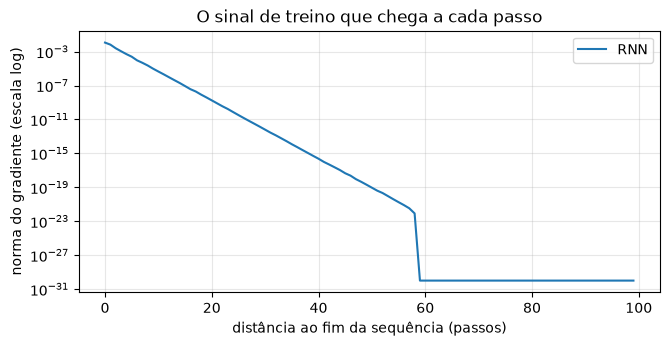

Passo 99 ( 0 passos antes do fim): gradiente 1.1e-02
Passo 90 ( 9 passos antes do fim): gradiente 9.7e-06
Passo 75 (24 passos antes do fim): gradiente 7.4e-11
Passo 50 (49 passos antes do fim): gradiente 2.0e-19
Passo  0 (99 passos antes do fim): gradiente 0.0e+00


In [6]:
# Executar esta célula

def gradiente_por_passo(tipo, T=100, semente=0):
    torch.manual_seed(semente)
    modelo = Recorrente(tipo)
    x, y = dados_memoria(256, T)
    entradas = modelo.embedding(x).detach().requires_grad_(True)
    estados, _ = modelo.camada(entradas)
    nn.CrossEntropyLoss()(modelo.saida(estados[:, -1]), y).backward()
    return entradas.grad.norm(dim=(0, 2)).numpy()  # norma do gradiente em cada passo t


g_rnn = gradiente_por_passo("RNN")
distancia = np.arange(100)[::-1]  # passos até ao fim da sequência
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.semilogy(distancia, np.maximum(g_rnn, 1e-30), label="RNN")  # os zeros não se desenham em escala log
ax.set_xlabel("distância ao fim da sequência (passos)")
ax.set_ylabel("norma do gradiente (escala log)")
ax.set_title("O sinal de treino que chega a cada passo")
ax.legend()
plt.show()
for t in (99, 90, 75, 50, 0):
    print(f"Passo {t:2d} ({99 - t:2d} passos antes do fim): gradiente {g_rnn[t]:.1e}")

Em escala logarítmica, a queda é quase uma reta: o gradiente diminui **exponencialmente** com a distância, cerca de uma ordem de grandeza a cada poucos passos. A 50 passos do fim já está na casa de $10^{-19}$, e ao primeiro passo, o único que importa nesta tarefa, chega literalmente **zero**: o número é tão pequeno que o formato `float32` não o consegue representar. A rede aprende o que está perto e é cega para o que está longe.

## 5. LSTM: uma memória com portas

### 5.1 A ideia

A **LSTM** (*long short-term memory*, Hochreiter e Schmidhuber, 1997) acrescenta à RNN um segundo estado, o **estado da célula** $C_t$, que funciona como uma passadeira rolante: atravessa a sequência sofrendo apenas pequenas alterações controladas por **portas**. Cada porta é uma camada com ativação sigmoide, por isso dá valores entre 0 (fechar) e 1 (deixar passar):

| Porta | Fórmula | O que decide |
| --- | --- | --- |
| esquecimento $f_t$ | $\sigma(W_f [h_{t-1}, x_t] + b_f)$ | quanto do estado da célula antigo se mantém |
| entrada $i_t$ | $\sigma(W_i [h_{t-1}, x_t] + b_i)$ | quanto da informação nova entra |
| candidato $g_t$ | $\tanh(W_g [h_{t-1}, x_t] + b_g)$ | a informação nova propriamente dita |
| saída $o_t$ | $\sigma(W_o [h_{t-1}, x_t] + b_o)$ | quanto do estado da célula se mostra em $h_t$ |

E as duas atualizações:

$$C_t = f_t \odot C_{t-1} + i_t \odot g_t$$

$$h_t = o_t \odot \tanh(C_t)$$

em que $\odot$ é o produto elemento a elemento. A chave está na primeira equação: o estado da célula é atualizado por **soma**, e não por uma multiplicação de matrizes seguida de tanh. Se a porta de esquecimento estiver perto de 1, $C_t \approx C_{t-1}$ e o gradiente atravessa muitos passos quase sem perdas. A rede **aprende** quando guardar ($f \approx 1$, $i \approx 0$) e quando escrever.

### 5.2 O gradiente na LSTM

A LSTM só guarda a memória se a porta de esquecimento estiver **aberta** ($f_t \approx 1$). Mas, acabada de inicializar, os seus vieses são pequenos e aleatórios, e a porta fica a meio ($\sigma(0) = 0{,}5$): em cada passo, o estado da célula perde cerca de metade, e ao fim de 100 passos não sobra nada. A solução habitual (Gers, Schmidhuber e Cummins, 2000; Jozefowicz, Zaremba e Sutskever, 2015) é **inicializar o viés da porta de esquecimento com um valor positivo**, para que a rede comece por lembrar e aprenda depois o que esquecer. Com um viés de 3, $f \approx \sigma(3) \approx 0{,}95$. É o parâmetro `vies_porta` da classe `Recorrente`.

Repetimos a medição da secção 4 para a LSTM com a inicialização habitual e com a porta de esquecimento aberta:

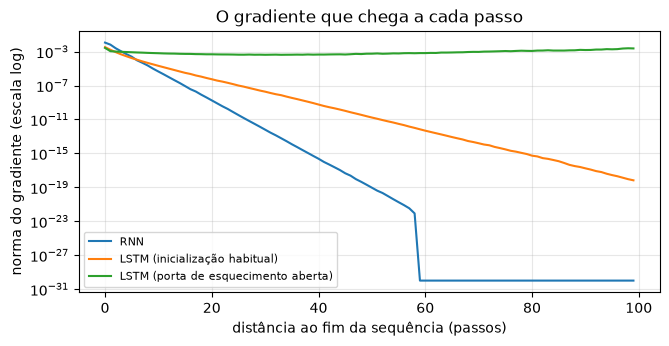

LSTM habitual: último passo 3.3e-03 | 50 passos antes 1.7e-11 | primeiro passo 6.6e-19
LSTM aberta  : último passo 2.7e-03 | 50 passos antes 5.7e-04 | primeiro passo 2.4e-03


In [7]:
# Executar esta célula

g_lstm = gradiente_por_passo("LSTM")
torch.manual_seed(0)
modelo_aberto = Recorrente("LSTM", vies_porta=3.0)
x, y = dados_memoria(256, 100)
entradas = modelo_aberto.embedding(x).detach().requires_grad_(True)
estados, _ = modelo_aberto.camada(entradas)
nn.CrossEntropyLoss()(modelo_aberto.saida(estados[:, -1]), y).backward()
g_lstm_aberta = entradas.grad.norm(dim=(0, 2)).numpy()

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for g, nome in ((g_rnn, "RNN"), (g_lstm, "LSTM (inicialização habitual)"), (g_lstm_aberta, "LSTM (porta de esquecimento aberta)")):
    ax.semilogy(distancia, np.maximum(g, 1e-30), label=nome)
ax.set_xlabel("distância ao fim da sequência (passos)")
ax.set_ylabel("norma do gradiente (escala log)")
ax.set_title("O gradiente que chega a cada passo")
ax.legend(fontsize=8)
plt.show()
for g, nome in ((g_lstm, "LSTM habitual"), (g_lstm_aberta, "LSTM aberta")):
    print(f"{nome:13s}: último passo {g[-1]:.1e} | 50 passos antes {g[49]:.1e} | primeiro passo {g[0]:.1e}")

Com a inicialização habitual, a LSTM desvanece quase tanto como a RNN: as portas ainda não sabem guardar. Com a porta de esquecimento aberta, a curva fica praticamente **plana**: o gradiente que chega ao primeiro passo é da mesma ordem de grandeza do que chega ao último. É a passadeira rolante do estado da célula a funcionar.

### 5.3 A LSTM na tarefa de memória

In [8]:
# Executar esta célula

inicio = time.process_time()
print(f"LSTM habitual, T =  20: exatidão {treinar(Recorrente('LSTM'), 20):.1%} | {time.process_time() - inicio:.1f} s")
for T in (5, 20, 50, 100):
    inicio = time.process_time()
    exatidao = treinar(Recorrente("LSTM", vies_porta=3.0), T)
    RESULTADOS[("LSTM", T)] = (exatidao, time.process_time() - inicio)
    print(f"LSTM aberta,   T = {T:3d}: exatidão {exatidao:.1%} | {RESULTADOS[('LSTM', T)][1]:.1f} s")

LSTM habitual, T =  20: exatidão 25.2% | 3.4 s


LSTM aberta,   T =   5: exatidão 100.0% | 2.1 s


LSTM aberta,   T =  20: exatidão 100.0% | 3.3 s


LSTM aberta,   T =  50: exatidão 100.0% | 5.3 s


LSTM aberta,   T = 100: exatidão 24.3% | 51.4 s


A LSTM com a inicialização habitual falha já com 20 passos, tal como a RNN: tem a arquitetura certa, mas não consegue descobrir, com este treino, que deve guardar. Com a porta de esquecimento aberta, resolve a tarefa até 50 passos. Com 100, volta aos 25 %: a memória da LSTM vai muito mais longe do que a da RNN, mas não é ilimitada, e aprender a usá-la fica mais difícil à medida que a distância cresce (numa experiência à parte, nem com 1500 passos de treino passou dos 25 %). Repara também que o tempo de treino cresce com $T$: a sequência tem de ser lida passo a passo, porque cada passo precisa do anterior, o que impede paralelizar no tempo.

A lição vai além da LSTM: **a arquitetura certa não chega; a inicialização e o treino também decidem se uma rede aprende**.

## 6. Atenção

### 6.1 A ideia: olhar diretamente para o passado

As redes recorrentes passam a informação de passo em passo, como num jogo do telefone estragado. A **atenção** propõe outra coisa: quando a rede precisa de uma informação, **olha diretamente** para todas as posições da sequência e escolhe as relevantes. A distância deixa de importar: o primeiro símbolo está a um passo de atenção do último, seja $T$ 5 ou 500.

Cada posição produz três vetores, por projeções lineares aprendidas: uma **consulta** $q$ («o que procuro?»), uma **chave** $k$ («o que tenho?») e um **valor** $v$ («o que dou, se for escolhido»). A relevância da posição $j$ para a posição $i$ é o produto interno $q_i \cdot k_j$. Normalizando com um *softmax*, obtêm-se pesos que somam 1, e a saída é a média ponderada dos valores:

$$\text{Atenção}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d}}\right) V$$

A divisão por $\sqrt{d}$ (a dimensão dos vetores) evita que os produtos internos cresçam com $d$ e saturem o *softmax*. Em código, é uma linha:

In [9]:
# Executar esta célula

def atencao(Q, K_, V):
    pesos = torch.softmax(Q @ K_.transpose(-2, -1) / math.sqrt(K_.shape[-1]), dim=-1)
    return pesos @ V, pesos


# Um exemplo à mão: 3 posições, vetores de dimensão 2
K_ex = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])  # chaves
V_ex = torch.tensor([[10.0, 0.0], [0.0, 10.0], [5.0, 5.0]])  # valores
Q_ex = torch.tensor([[4.0, 0.0]])  # uma consulta que «procura» a primeira direção
saida, pesos = atencao(Q_ex, K_ex, V_ex)
print("Pesos de atenção:", pesos.numpy().round(3))
print("Saída (média ponderada dos valores):", saida.numpy().round(2))

Pesos de atenção: [[0.486 0.029 0.486]]
Saída (média ponderada dos valores): [[7.28 2.72]]


A consulta $(4, 0)$ alinha-se com as chaves da primeira e da terceira posições e ignora quase totalmente a segunda: a saída é sobretudo uma mistura dos valores dessas duas.

### 6.2 A ordem: codificação posicional

A atenção, sozinha, **não sabe a ordem**: se baralharmos as posições, os pesos mudam de lugar mas a média ponderada é a mesma. É um viés indutivo de **conjunto**, não de sequência. Para a nossa tarefa («qual era o primeiro?»), isso seria fatal. A solução de Vaswani et al. (2017) é somar a cada *embedding* um vetor que depende só da posição, feito de senos e cossenos de frequências diferentes:

$$PE_{(p,\,2i)} = \sin\!\left(p / 10000^{2i/d}\right) \qquad PE_{(p,\,2i+1)} = \cos\!\left(p / 10000^{2i/d}\right)$$

Cada posição fica com uma «impressão digital» única, e posições próximas têm vetores parecidos.

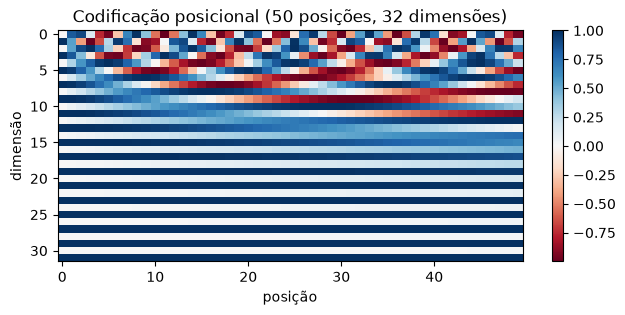

In [10]:
# Executar esta célula

def codificacao_posicional(T, d):
    posicao = torch.arange(T).unsqueeze(1)
    angulos = posicao / (10000 ** (torch.arange(0, d, 2) / d))
    pe = torch.zeros(T, d)
    pe[:, 0::2] = torch.sin(angulos)
    pe[:, 1::2] = torch.cos(angulos)
    return pe


fig, ax = plt.subplots(figsize=(7.5, 3))
im = ax.imshow(codificacao_posicional(50, 32).T, aspect="auto", cmap="RdBu")
ax.set_xlabel("posição")
ax.set_ylabel("dimensão")
ax.set_title("Codificação posicional (50 posições, 32 dimensões)")
ax.grid(False)
fig.colorbar(im, ax=ax)
plt.show()

### 6.3 Um modelo de atenção para a tarefa de memória

O modelo é deliberadamente mínimo: *embedding* mais codificação posicional, **uma** cabeça de atenção em que só a última posição faz a consulta (é aí que a resposta é dada), e uma camada densa. Não há recorrência: todas as posições são processadas ao mesmo tempo. Guardamos os pesos de atenção para os desenhar.

In [11]:
# Executar esta célula

class ModeloAtencao(nn.Module):
    def __init__(self, d=32, usar_posicao=True):
        super().__init__()
        self.embedding = nn.Embedding(K, d)
        self.consulta, self.chave, self.valor = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.saida = nn.Linear(d, K)
        self.usar_posicao = usar_posicao
        self.pesos = None

    def forward(self, x):
        e = self.embedding(x)
        if self.usar_posicao:
            e = e + codificacao_posicional(x.shape[1], e.shape[-1])
        resumo, pesos = atencao(self.consulta(e[:, -1:]), self.chave(e), self.valor(e))
        self.pesos = pesos.detach()[:, 0]  # (N, T): quanto a última posição olha para cada posição
        return self.saida(resumo[:, 0])


for T in (5, 20, 50, 100):
    inicio = time.process_time()
    exatidao = treinar(ModeloAtencao(), T)
    RESULTADOS[("Atenção", T)] = (exatidao, time.process_time() - inicio)
    print(f"Atenção, T = {T:3d}: exatidão {exatidao:.1%} | {RESULTADOS[('Atenção', T)][1]:.1f} s")

Atenção, T =   5: exatidão 100.0% | 2.1 s


Atenção, T =  20: exatidão 100.0% | 2.6 s


Atenção, T =  50: exatidão 100.0% | 3.0 s


Atenção, T = 100: exatidão 100.0% | 4.0 s


O que aprendeu a rede? Para uma sequência de 50 símbolos, desenhamos os pesos de atenção da última posição:

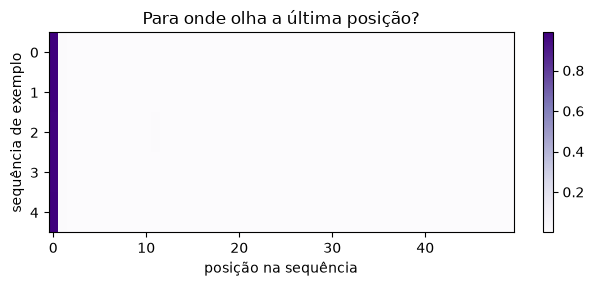

Peso médio na posição 0: 0.984
Respostas certas: [2, 1, 1, 0, 1] | previstas: [2, 1, 1, 0, 1]


In [12]:
# Executar esta célula

torch.manual_seed(0)
modelo_att = ModeloAtencao()
treinar(modelo_att, T=50)
x, y = dados_memoria(5, 50, semente=123)
with torch.no_grad():
    previsao = modelo_att(x).argmax(1)

fig, ax = plt.subplots(figsize=(7.5, 2.6))
im = ax.imshow(modelo_att.pesos.numpy(), aspect="auto", cmap="Purples")
ax.set_xlabel("posição na sequência")
ax.set_ylabel("sequência de exemplo")
ax.set_title("Para onde olha a última posição?")
ax.grid(False)
fig.colorbar(im, ax=ax)
plt.show()
print("Peso médio na posição 0:", modelo_att.pesos[:, 0].mean().item().__round__(3))
print("Respostas certas:", y.tolist(), "| previstas:", previsao.tolist())

A rede descobriu sozinha a solução: concentra quase toda a atenção na **posição 0** e ignora o resto. Não precisou de transportar a informação ao longo de 50 passos, porque foi buscá-la diretamente.

### 6.4 Do bloco de atenção ao *transformer*

O nosso modelo tem uma só cabeça de atenção e só a última posição consulta. Um ***transformer*** (Vaswani et al., 2017), como os do N3_07, empilha muitos **blocos** como este, com quatro acrescentos:

- **todas** as posições consultam todas as outras (a matriz de atenção é $T \times T$);
- **várias cabeças** em paralelo (*multi-head*), cada uma livre de aprender um tipo de relação diferente;
- uma pequena **rede densa** depois da atenção, em cada posição;
- **ligações residuais** e **normalização de camada**, que permitem empilhar dezenas de blocos e treinar de forma estável.

O PyTorch tem o bloco pronto: `nn.TransformerEncoderLayer(d_model=32, nhead=4, batch_first=True)`. O preço da atenção é o custo $O(T^2)$ (cada posição olha para todas), contra $O(T)$ das redes recorrentes. A vantagem é que esses $T^2$ cálculos se fazem **todos ao mesmo tempo**, o que se adapta perfeitamente às GPU. É esta combinação, e não a atenção sozinha, que tornou possíveis os grandes modelos de linguagem.

## 7. Comparação e síntese

Juntamos os resultados das secções 3, 5 e 6 (a LSTM é a versão com a porta de esquecimento aberta):

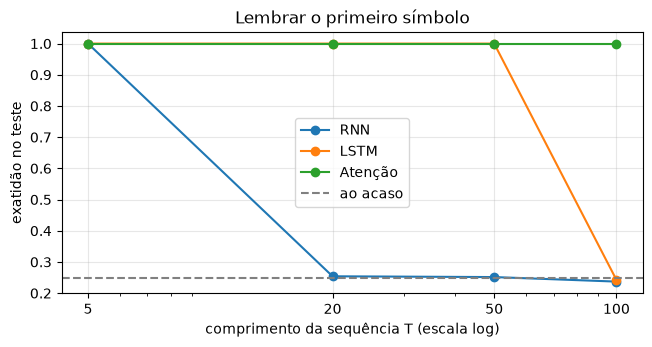

exatidão               tempo (s)               
arquitetura      RNN  LSTM Atenção       RNN   LSTM Atenção
T                                                          
5               1.00  1.00     1.0      2.92   2.14    2.10
20              0.25  1.00     1.0      2.90   3.25    2.56
50              0.25  1.00     1.0      5.08   5.31    3.04
100             0.24  0.24     1.0      8.71  51.35    4.00

In [13]:
# Executar esta célula

comparacao = pd.DataFrame([{"T": T, "arquitetura": nome, "exatidão": exatidao, "tempo (s)": tempo}
                           for (nome, T), (exatidao, tempo) in RESULTADOS.items()])

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for nome, grupo in comparacao.groupby("arquitetura", sort=False):
    ax.plot(grupo["T"], grupo["exatidão"], marker="o", label=nome)
ax.axhline(1 / K, color="gray", linestyle="--", label="ao acaso")
ax.set_xscale("log")
ax.set_xticks([5, 20, 50, 100], ["5", "20", "50", "100"])
ax.set_xlabel("comprimento da sequência T (escala log)")
ax.set_ylabel("exatidão no teste")
ax.set_title("Lembrar o primeiro símbolo")
ax.legend()
plt.show()
tabela = comparacao.pivot(index="T", columns="arquitetura", values=["exatidão", "tempo (s)"]).round(2)
tabela[[("exatidão", n) for n in ("RNN", "LSTM", "Atenção")] + [("tempo (s)", n) for n in ("RNN", "LSTM", "Atenção")]]

| | RNN | LSTM | Atenção (*transformer*) |
| --- | --- | --- | --- |
| Como guarda o passado | um estado escondido, reescrito em cada passo | um estado da célula, protegido por portas | não guarda: consulta diretamente todas as posições |
| Dependências longas | difíceis (o gradiente desvanece) | muito melhores, mas com limite, e dependem da inicialização | sem dificuldade de distância |
| Paralelismo no tempo | não (passo a passo) | não (passo a passo) | sim (todas as posições ao mesmo tempo) |
| Custo por sequência | $O(T)$ | $O(T)$ | $O(T^2)$ |
| Ordem | implícita na leitura | implícita na leitura | precisa de codificação posicional |
| Onde se usa hoje | sistemas pequenos, sinais em tempo real | séries temporais, áudio, dispositivos com pouca memória | texto, tradução, código, imagem, grandes modelos de linguagem |

Duas notas finais. Primeiro, a tarefa de memória foi escolhida para separar as arquiteturas; em tarefas em que só importa o passado recente (prever a temperatura de amanhã a partir dos últimos dias), uma RNN simples ou até um modelo linear podem bastar, e são muito mais baratos. Segundo, a LSTM não ficou obsoleta: em sequências muito longas e em dispositivos com pouca memória, o custo $O(T)$ continua a ser uma vantagem, e há investigação recente a recuperar ideias recorrentes precisamente por isso.

## 8. Experimenta

### Exercício 1 – A GRU

A **GRU** (*gated recurrent unit*, Cho et al., 2014) é uma simplificação da LSTM: junta as portas de esquecimento e de entrada numa só porta de atualização e não tem estado da célula separado. Treina a GRU na tarefa de memória com T = 20 e 50, com a inicialização habitual e com `vies_porta=3.0`, e compara com a LSTM em exatidão e número de parâmetros. (Na GRU do PyTorch, o segundo bloco de vieses é a porta de **atualização**; com ela perto de 1, a GRU mantém o estado anterior, que é o equivalente a abrir a porta de esquecimento.)

In [14]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for tipo in ("LSTM", "GRU"):
    parametros = sum(p.numel() for p in Recorrente(tipo).parameters())
    for vies in (None, 3.0):
        resultados = {T: round(treinar(Recorrente(tipo, vies_porta=vies), T), 3) for T in (20, 50)}
        print(f"{tipo} ({parametros} parâmetros), vies_porta={vies}: exatidão por T {resultados}")
```

A GRU tem cerca de três quartos dos parâmetros da LSTM (3 conjuntos de pesos em vez de 4). Tal como a LSTM, falha com a inicialização habitual e resolve a tarefa até 50 passos com a porta de atualização aberta. Na prática, as duas dão resultados parecidos na maioria dos problemas; a GRU é mais leve, a LSTM um pouco mais expressiva.

</details>

### Exercício 2 – Atenção sem posições

Treina o `ModeloAtencao(usar_posicao=False)` com T = 20 e compara a exatidão com a versão com codificação posicional. Explica o resultado.

In [15]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for usar in (True, False):
    exatidao = treinar(ModeloAtencao(usar_posicao=usar), T=20)
    print(f"Com codificação posicional = {usar}: exatidão {exatidao:.1%}")
```

Sem codificação posicional, a exatidão cai para perto dos 25 % do acaso, ou pouco acima. A atenção calcula uma média ponderada que não depende da ordem das posições: para ela, a sequência é um **conjunto** de símbolos, e «o primeiro» não tem significado. O pouco acima do acaso vem de a última posição ser tratada de forma especial (é ela que consulta). A codificação posicional é o que transforma um modelo de conjuntos num modelo de sequências.

</details>

### Exercício 3 – Prever uma série temporal

As redes recorrentes também fazem **regressão**. Gera uma série $y_t = \sin(0{,}2t) + 0{,}5\sin(0{,}05t)$ com algum ruído, corta-a em janelas de 30 valores e treina uma LSTM para prever o valor seguinte de cada janela. Compara o erro com uma referência ingénua (prever que o próximo valor é igual ao último).

In [16]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
torch.manual_seed(0)
t = torch.arange(3000, dtype=torch.float32)
serie = torch.sin(0.2 * t) + 0.5 * torch.sin(0.05 * t) + 0.05 * torch.randn(3000)
janelas = serie.unfold(0, 31, 1)  # janelas de 31: 30 de entrada + 1 alvo
X, Y = janelas[:, :30].unsqueeze(-1), janelas[:, 30]
X_treino, Y_treino, X_teste, Y_teste = X[:2400], Y[:2400], X[2400:], Y[2400:]  # o teste é o futuro


class Previsor(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 32, batch_first=True)
        self.saida = nn.Linear(32, 1)

    def forward(self, x):
        h, _ = self.lstm(x)
        return self.saida(h[:, -1]).squeeze(-1)


previsor = Previsor()
otimizador = torch.optim.Adam(previsor.parameters(), lr=1e-2)
for epoca in range(40):
    for i in range(0, 2400, 100):
        otimizador.zero_grad()
        nn.functional.mse_loss(previsor(X_treino[i:i + 100]), Y_treino[i:i + 100]).backward()
        otimizador.step()

with torch.no_grad():
    erro_lstm = (previsor(X_teste) - Y_teste).abs().mean().item()
erro_ingenuo = (X_teste[:, -1, 0] - Y_teste).abs().mean().item()
print(f"Erro absoluto médio no teste: LSTM {erro_lstm:.3f} | ingénuo (último valor) {erro_ingenuo:.3f}")
```

A LSTM erra bastante menos do que a referência ingénua, porque aprende o ritmo das duas ondas e não apenas que o próximo valor é parecido com o último. Repara que o teste é o **fim** da série, não uma amostra ao acaso: numa série temporal, misturar o futuro no treino daria uma avaliação otimista (a mesma fuga de informação do N3_03).

</details>

## Verifica o que aprendeste

1. O que é o viés indutivo de uma arquitetura? Dá o de uma CNN e o de uma RNN.
2. Porque é que uma rede densa não é adequada para sequências de comprimento variável?
3. Escreve a equação da RNN. Porque é que o número de parâmetros não depende de $T$?
4. O que é o desvanecimento do gradiente, e porque acontece nas RNN? E a explosão do gradiente, como se resolve?
5. Que papel tem o estado da célula na LSTM, e porque é que a sua atualização por soma ajuda o gradiente?
6. Para que servem as portas de esquecimento, de entrada e de saída?
7. Escreve a fórmula da atenção e explica o papel de $Q$, $K$, $V$ e de $\sqrt{d}$.
8. Porque é que a atenção precisa de codificação posicional?
9. Na tarefa de memória, porque é que a atenção não sofre com o aumento de $T$?
10. Quais são as vantagens e o custo da atenção em relação às redes recorrentes?
11. Que acrescenta um *transformer* ao bloco de atenção simples deste módulo?

<details>
<summary><b>Ver respostas</b></summary>

1. É o que a arquitetura assume sobre os dados antes de os ver. A CNN assume que os padrões são locais e iguais em qualquer posição da imagem; a RNN assume que os dados são uma sequência ordenada e que o passado se pode resumir num estado.
2. Porque tem um número fixo de entradas, aprende pesos separados para cada posição (sem partilhar o que aprende) e o número de parâmetros cresce com o comprimento.
3. $h_t = \tanh(W_h h_{t-1} + W_x x_t + b)$. Os mesmos pesos são usados em todos os passos.
4. O gradiente que chega aos passos antigos é um produto de muitos fatores; se forem em média menores do que 1, decresce exponencialmente com a distância, e a rede não aprende dependências longas. A explosão (fatores maiores do que 1) resolve-se com o corte do gradiente.
5. É uma memória de longo prazo, atualizada por $C_t = f_t \odot C_{t-1} + i_t \odot g_t$. Com a porta de esquecimento perto de 1, $C_t \approx C_{t-1}$, e o gradiente atravessa muitos passos quase sem se atenuar. Por isso se inicializa o viés dessa porta com um valor positivo: a rede começa por lembrar.
6. A de esquecimento decide quanto do estado antigo se mantém; a de entrada, quanto da informação nova entra; a de saída, quanto do estado da célula aparece no estado escondido.
7. $\text{softmax}(QK^T/\sqrt{d})\,V$. As consultas perguntam, as chaves medem a relevância de cada posição para cada consulta, os valores são o que se mistura. A divisão por $\sqrt{d}$ impede que os produtos internos cresçam com a dimensão e saturem o *softmax*.
8. Porque a média ponderada não depende da ordem das posições: sem posições, a atenção vê um conjunto, não uma sequência.
9. Porque a última posição consulta diretamente a posição 0; a informação não tem de atravessar os passos intermédios.
10. Vantagens: dependências a qualquer distância e cálculo em paralelo de todas as posições. Custo: $O(T^2)$ em tempo e memória, contra $O(T)$ das recorrentes.
11. Atenção de todas as posições para todas, várias cabeças em paralelo, uma rede densa por posição, ligações residuais e normalização de camada, empilhados em muitos blocos.

</details>

## Leitura recomendada

- Goodfellow, I., Bengio, Y. e Courville, A. (2016). *[Deep Learning](https://www.deeplearningbook.org/)*. Cambridge: MIT Press. Capítulo 10 (modelação de sequências: redes recorrentes e LSTM). Disponível gratuitamente online.
- Zhang, A., Lipton, Z. C., Li, M. e Smola, A. J. *[Dive into Deep Learning](https://d2l.ai/)*. Capítulos 9 a 11 (RNN, RNN modernas, atenção e *transformers*), com código em PyTorch. Gratuito.
- Bengio, Y., Simard, P. e Frasconi, P. (1994). [Learning long-term dependencies with gradient descent is difficult](https://doi.org/10.1109/72.279181). *IEEE Transactions on Neural Networks*, 5(2), 157–166.
- Jozefowicz, R., Zaremba, W. e Sutskever, I. (2015). [An empirical exploration of recurrent network architectures](https://proceedings.mlr.press/v37/jozefowicz15.html). *ICML 2015*. Inclui a recomendação de inicializar a porta de esquecimento com viés positivo.
- Hochreiter, S. e Schmidhuber, J. (1997). [Long short-term memory](https://doi.org/10.1162/neco.1997.9.8.1735). *Neural Computation*, 9(8), 1735–1780.
- Vaswani, A. et al. (2017). [Attention is all you need](https://arxiv.org/abs/1706.03762). *Advances in Neural Information Processing Systems*, 30.
- [Documentação do PyTorch: `nn.RNN`, `nn.LSTM`, `nn.GRU` e `nn.TransformerEncoderLayer`](https://pytorch.org/docs/stable/nn.html#recurrent-layers).
- **Módulos relacionados:** N3_04 e N3_05 (redes e treino), N3_06 (CNN), N3_07 (texto e *transformers* pré-treinados), N3_13 (autoencoders, GAN e GNN).